In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
import glob

## Trends

In [2]:
# df_kinetic = pd.read_pickle(f'files/processed/all_distributions_151025.pkl')
# df_grouped_kinetic = pd.read_pickle(f'files/processed/all_distributions_summary_151025.pkl')

# df_kinetic_flow = pd.read_pickle(f'files/processed/all_distributions_151025_flow.pkl')
# df_grouped_kinetic_flow = pd.read_pickle(f'files/processed/all_distributions_summary_151025_flow.pkl')
df = pd.read_pickle(f'files/processed/all_distributions_summary_081225.pkl')

df_grouped_kinetic_flow = df[df.is_stream]
df_grouped_kinetic = df[~df.is_stream]

boltzman_distr_df = pd.read_pickle('files/processed/boltzman_distr_071025_16.pkl')
df_grouped_boltzman = pd.read_pickle('files/processed/boltzman_distr_summary_071025_16.pkl')

ts = pd.DataFrame()
for temperature in [300, 360, 390, 420]:
    tst = pd.read_pickle(f'files/processed/ts_century_run_c16_temperature_{temperature}_pressure_1.pkl')
    tst['temperature'] = temperature
    tst = tst.reset_index(names=['time'])
    ts = pd.concat([ts, tst], ignore_index=True)

ts = ts.melt(id_vars=['time', 'temperature'], var_name='olefin', value_name='concentration')
ts['n'] = ts['olefin'].apply(lambda x: int(x[1:]))

<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
<>:32: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_12313/3444020097.py:32: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$', r'$\infty$$~nm$'), axs):
/tmp/ipykernel_12313/3444020097.py:32: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$', r'$\infty$$~nm$'), axs):


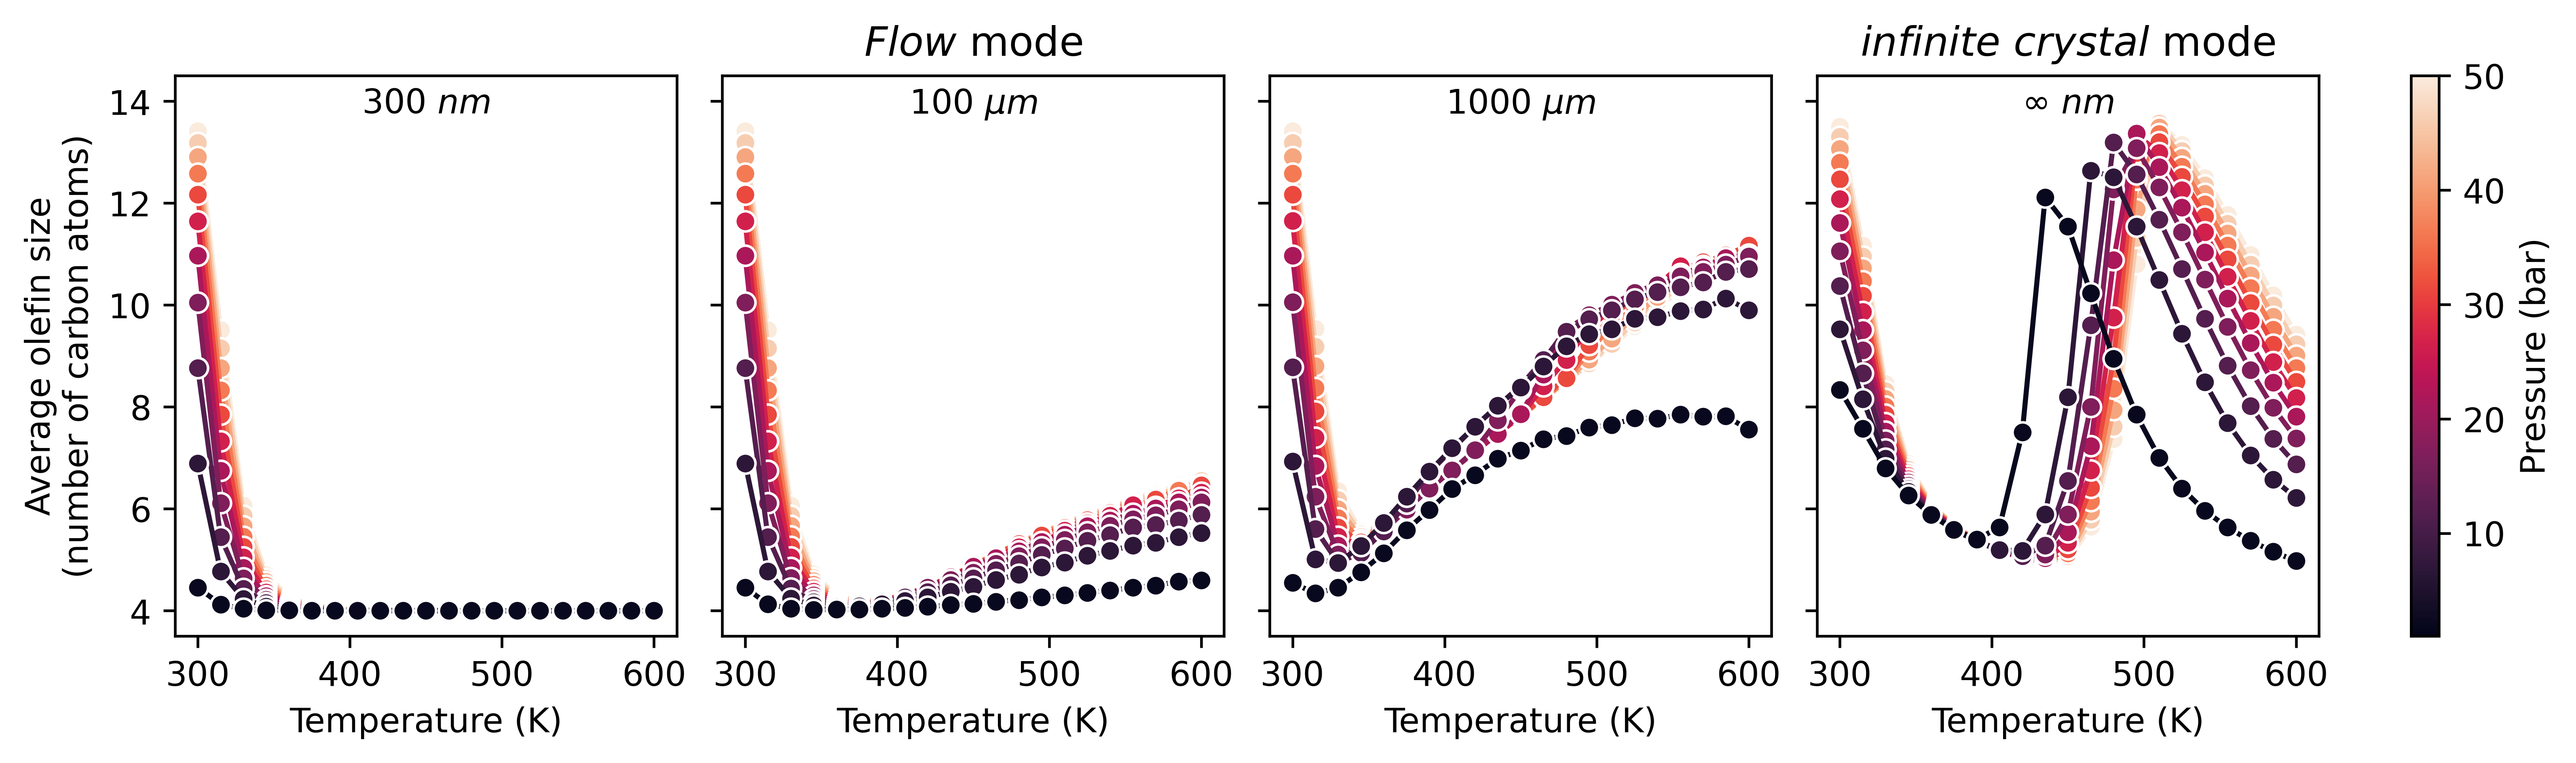

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3), dpi=600, sharey=True)

cmap = "rocket_r"
cmap_colormap = "rocket"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, True, axs[0]),
    (int(1e5), True, True, axs[1]),
    (int(1e6), True, True, axs[2]),
    (300, False, False, axs[3]),
]):
    if not is_stream:
        df = df_grouped_kinetic
    else:
        df = df_grouped_kinetic_flow

    data = df.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == 0.01')
    data.loc[:, 'pressure'] = 50 - data.pressure
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$', r'$\infty$$~nm$'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.text(
    0.5, 0.98, title,
    transform=ax.transAxes,
    ha='center', va='top')
    ax.set_ylim([3.5, 14.5])


axs[0].set_ylabel('Average olefin size\n(number of carbon atoms)')
sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])
axs[1].set_title('$Flow$ mode')
axs[3].set_title('$infinite~crystal$ mode')
cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En.png", bbox_inches="tight")

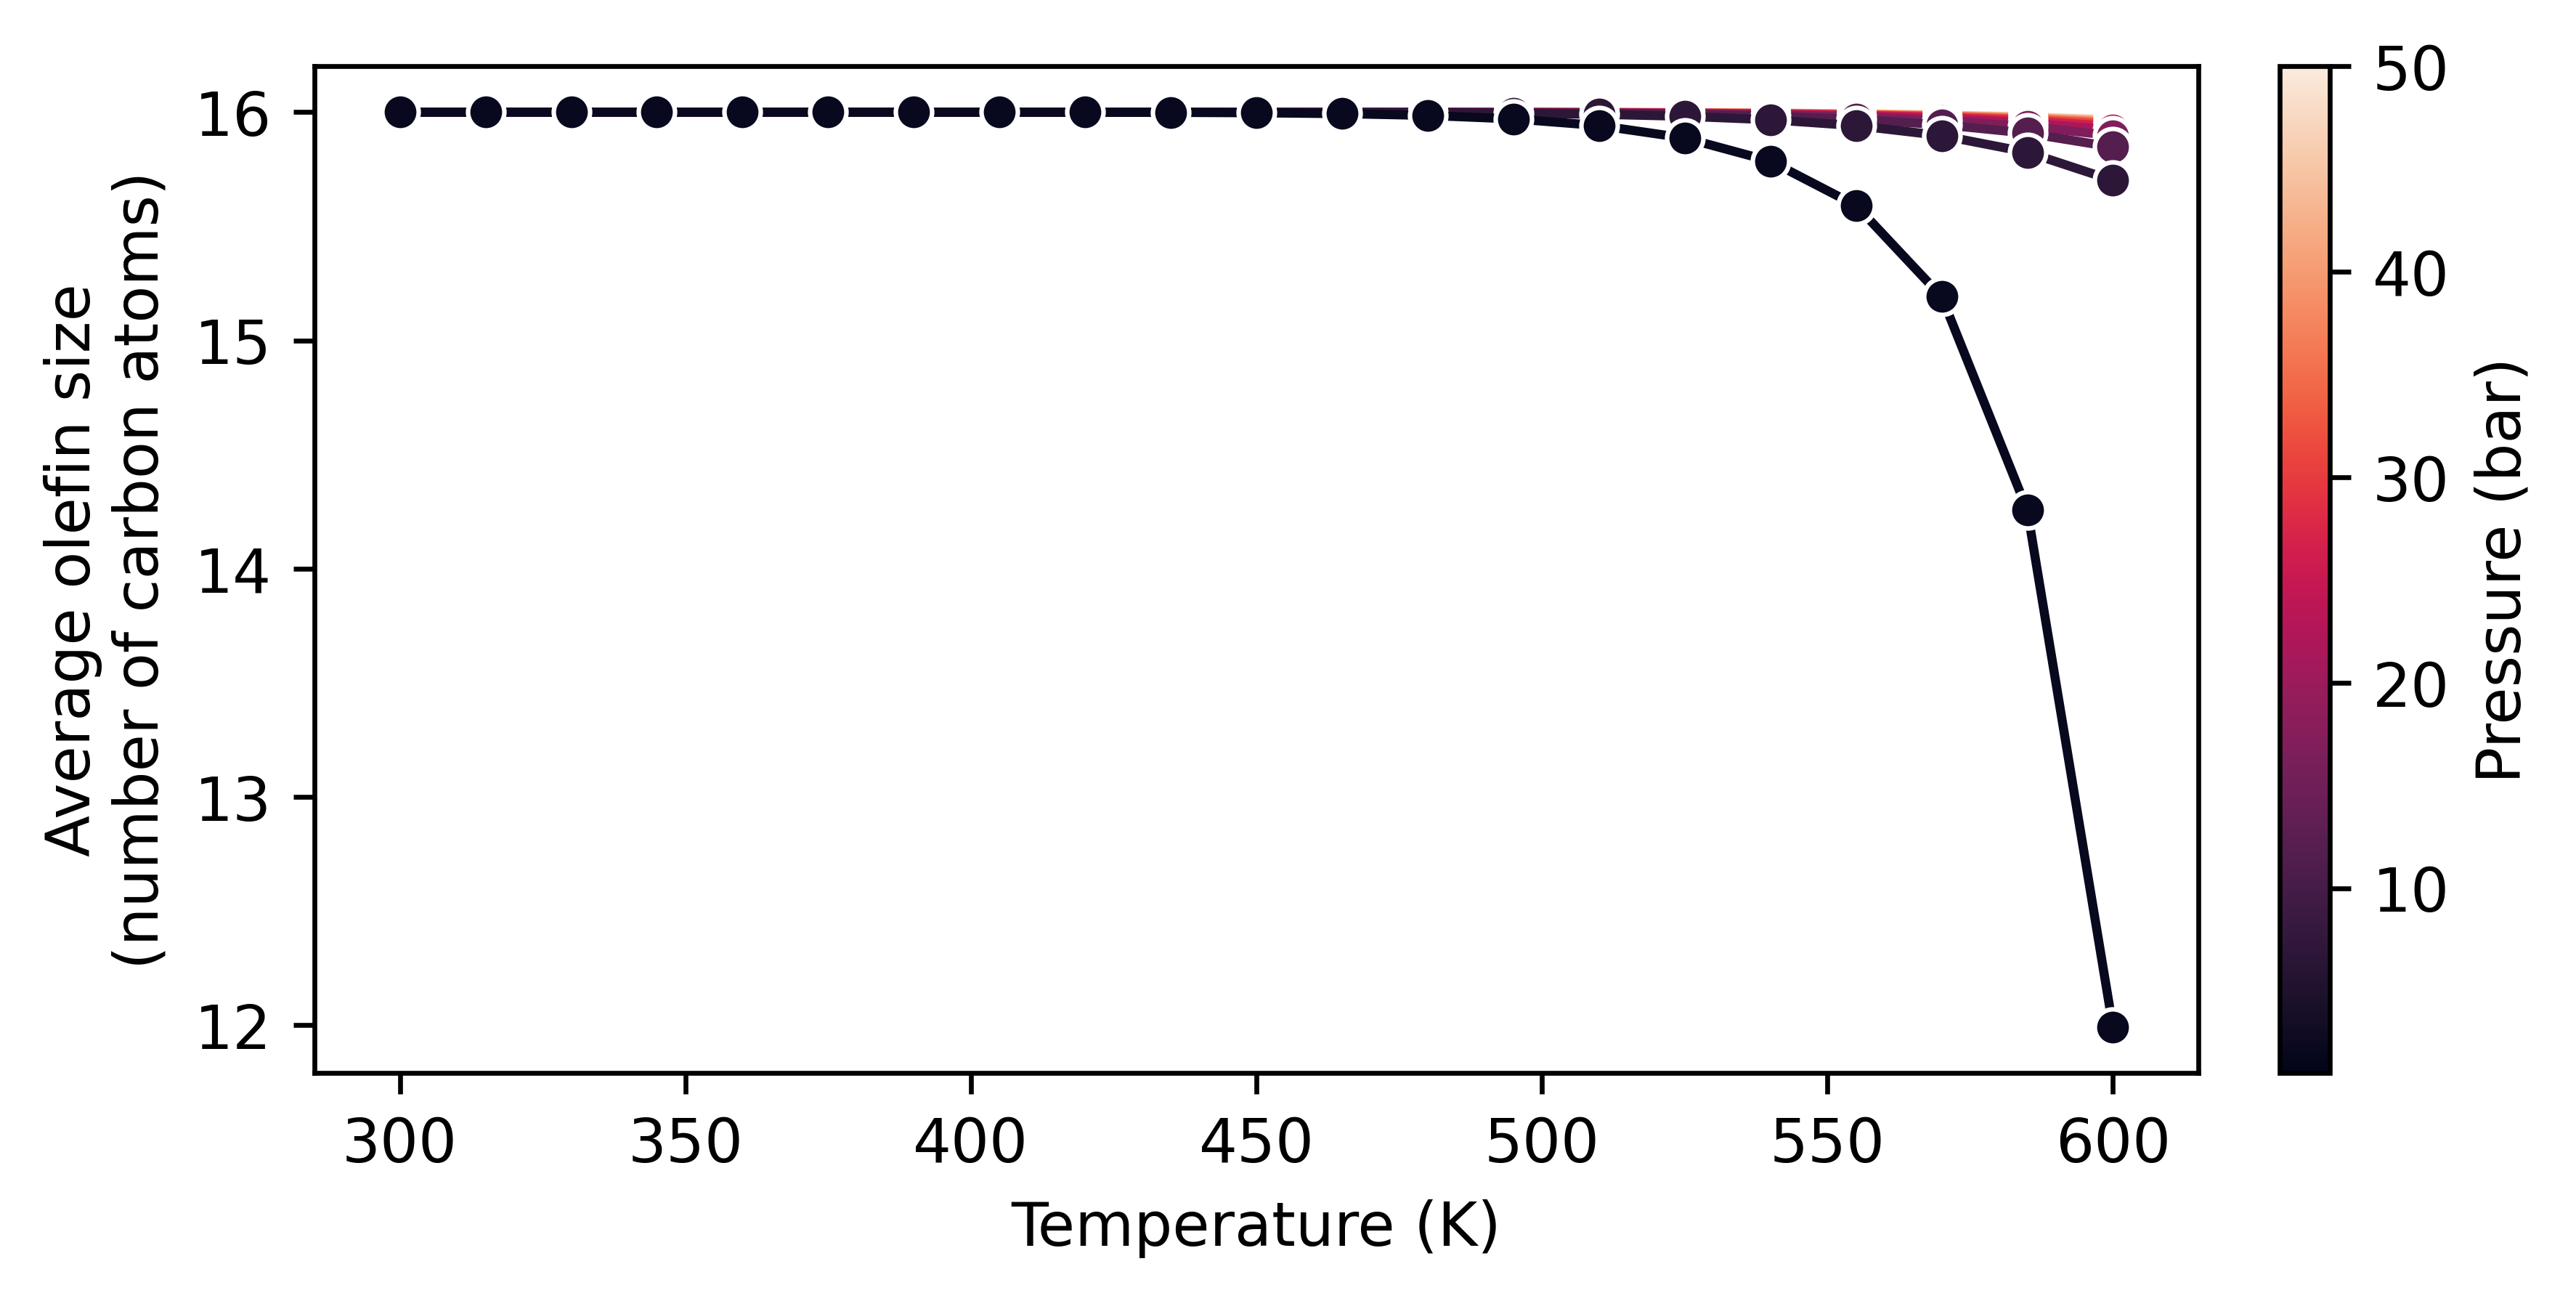

In [19]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3), dpi=600, sharey=True)


norm = mpl.colors.Normalize(vmin=1, vmax=50)


data = df_grouped_boltzman
data.loc[:, 'pressure'] = 50 - data.pressure
# Sort so higher pressure values are plotted first (smaller pressures above)
sns.lineplot(
    data=data,
    x='temperature', y='expected_n', hue='pressure',
    hue_order=sorted(data['pressure'].unique(), reverse=False),
    hue_norm=norm,
    marker='o', ax=ax,
    palette=sns.color_palette(cmap, as_cmap=True),
    
)


ax.set_xlabel('Temperature (K)')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()
ax.set_title('')

ax.set_ylabel('Average olefin size\n(number of carbon atoms)')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_boltzmann_En.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_boltzmann_En.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_boltzmann_En.png", bbox_inches="tight")

<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_12313/2051286030.py:31: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$', r'$\infty$$~nm$'), axs):
/tmp/ipykernel_12313/2051286030.py:31: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$', r'$\infty$$~nm$'), axs):


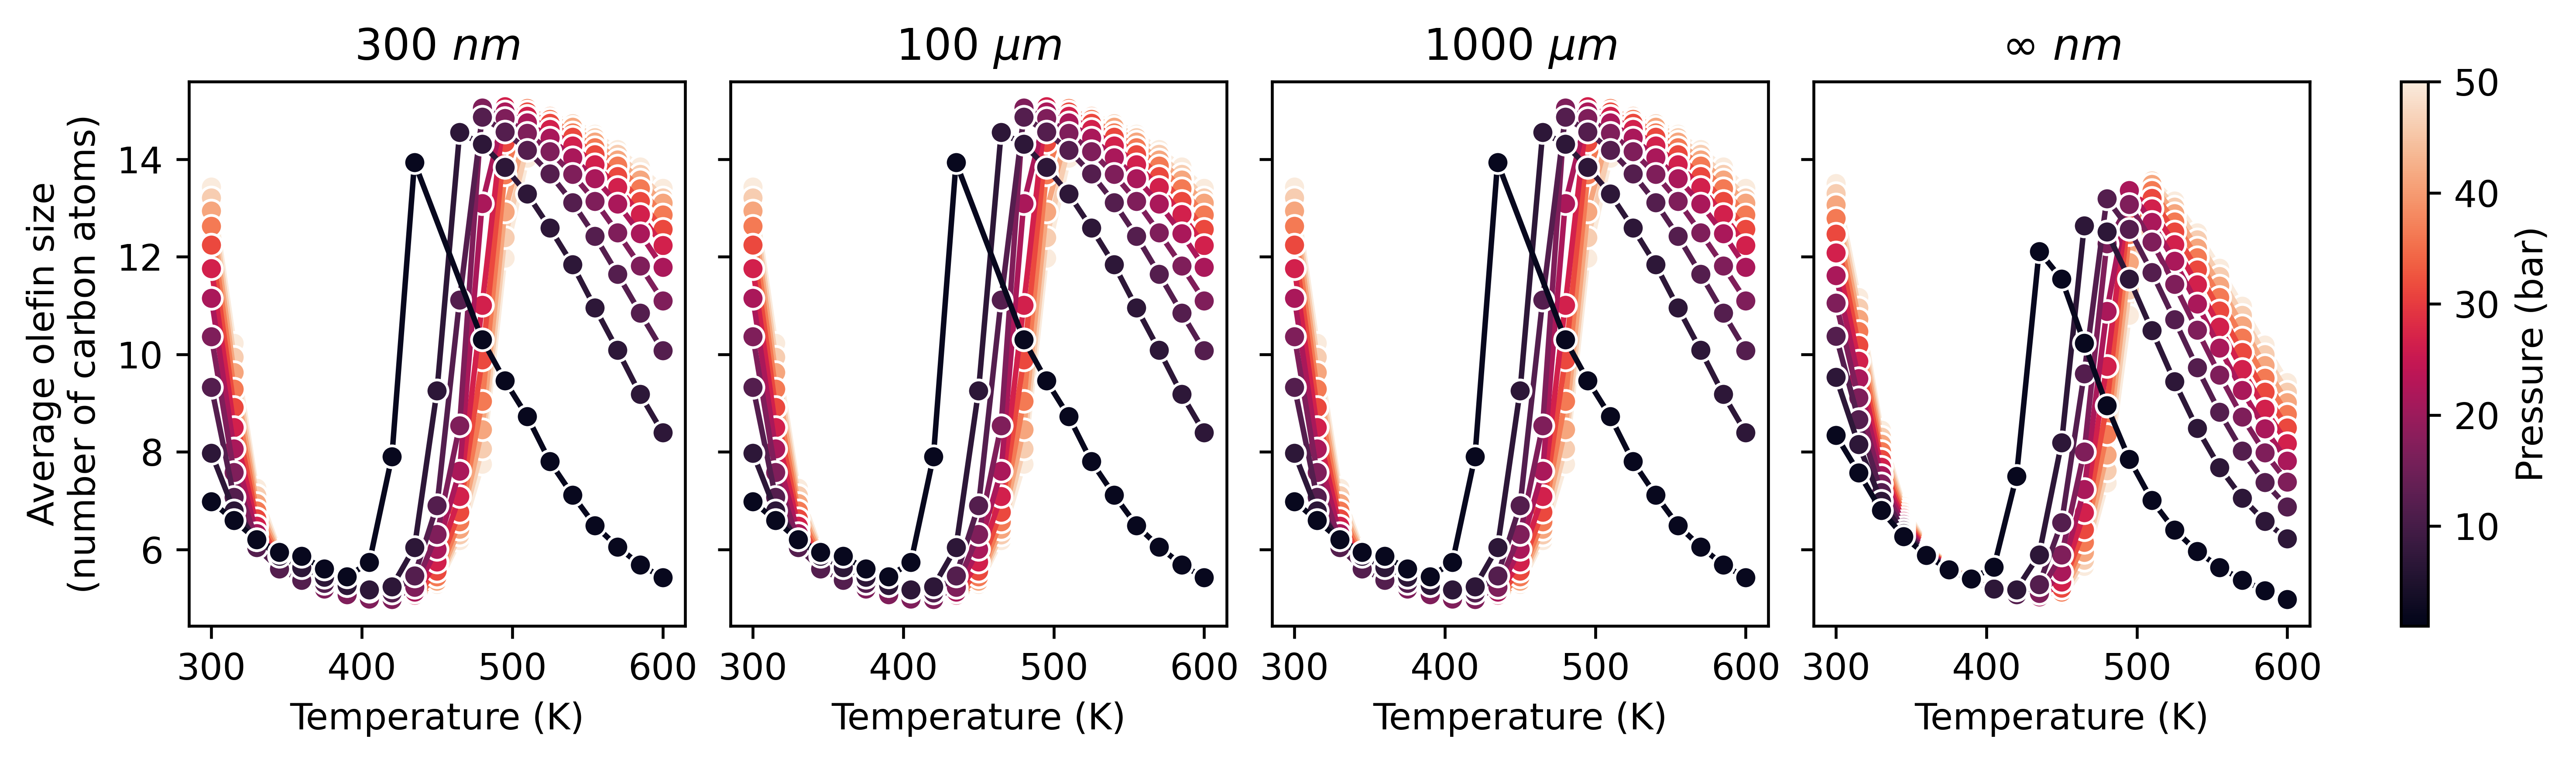

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(11, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, False, axs[0]),
    (int(1e5), True, False, axs[1]),
    (int(1e6), True, False, axs[2]),
    (300, False, False, axs[3]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    data.loc[:, 'pressure'] = 50 - data.pressure
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('$300~nm$ batch mode', '$100 \mu m$ batch mode', '1000$\mu$m batch mode', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Average olefin size\n(number of carbon atoms)')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI.png", bbox_inches="tight")

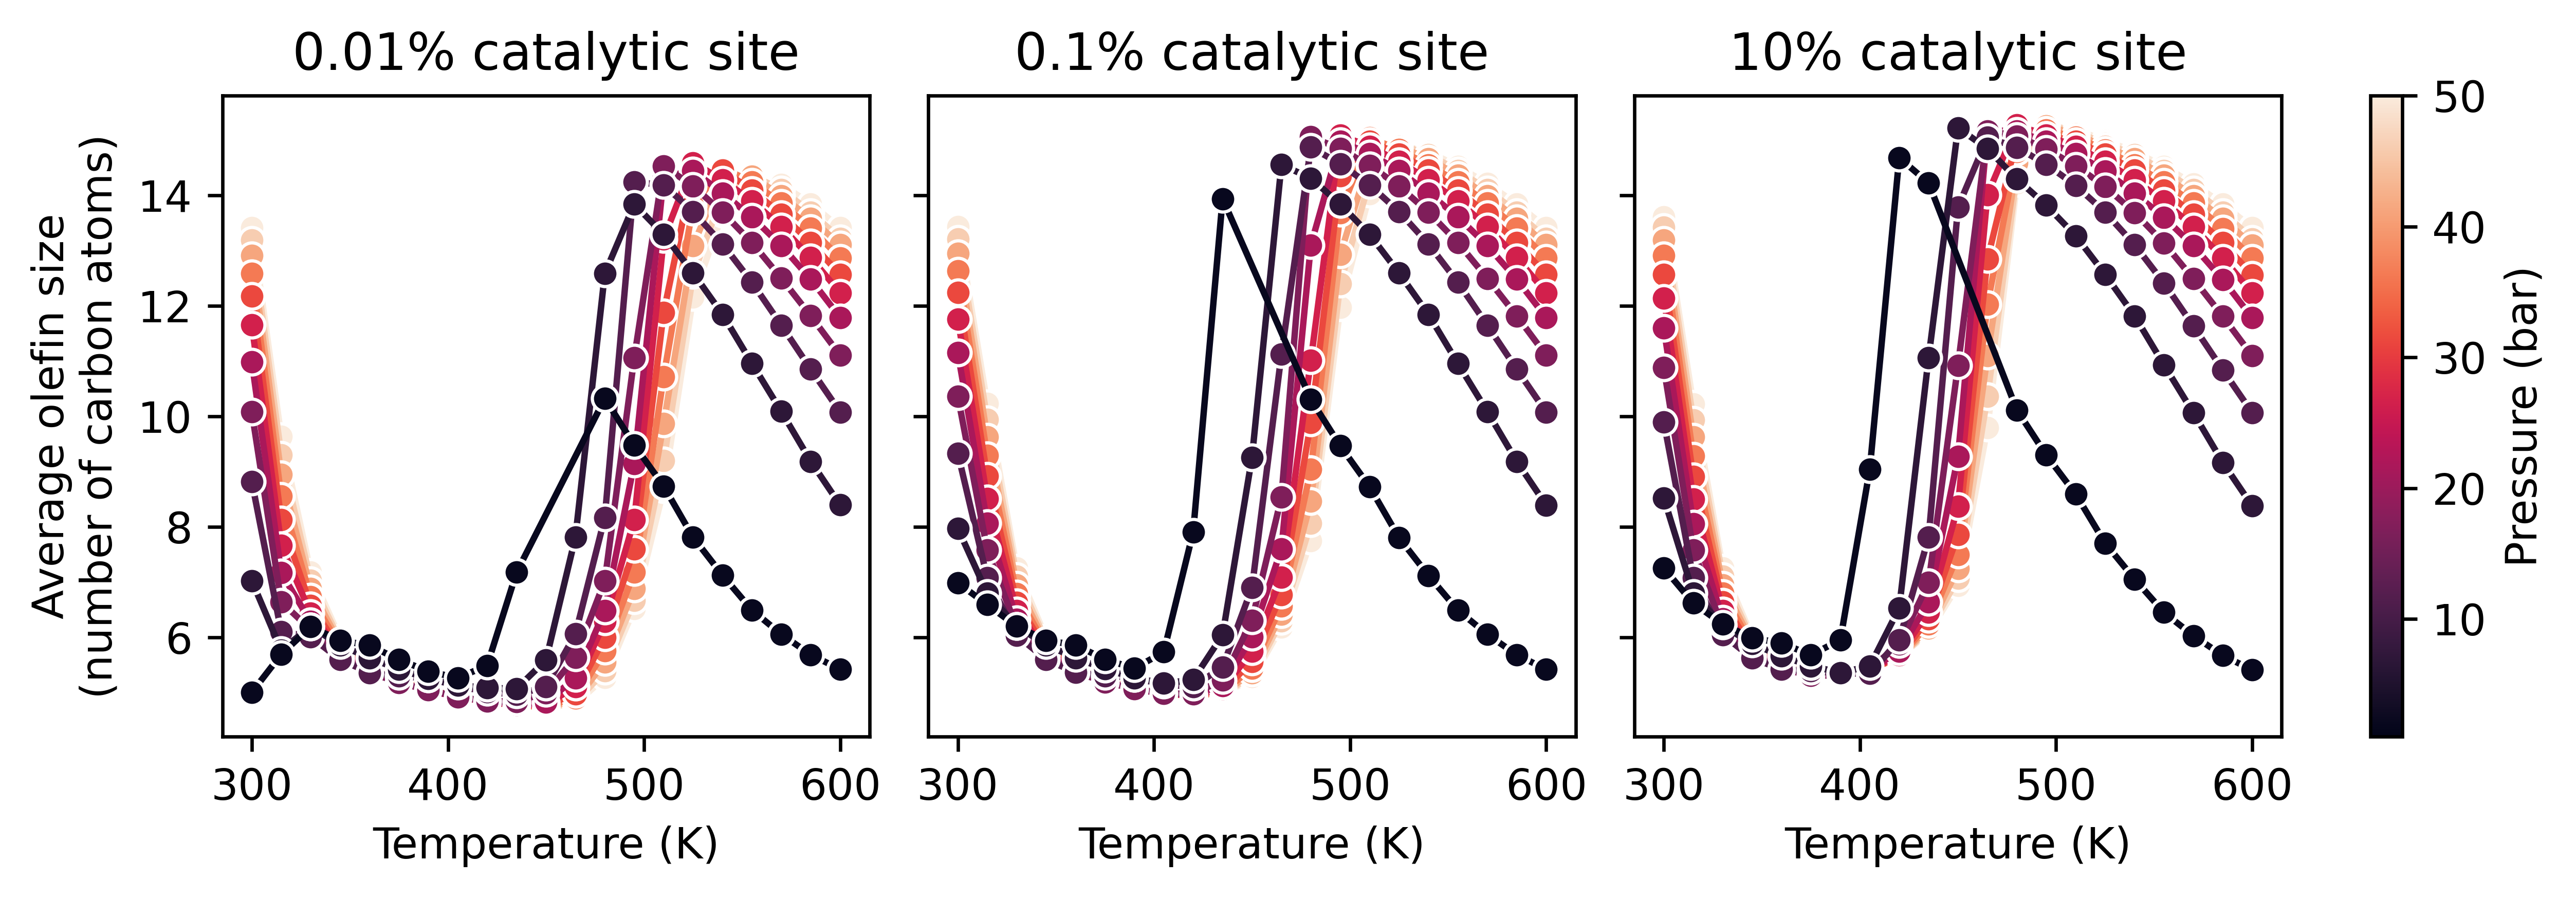

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic#.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, cat_conc, ax) in enumerate([
    (int(1e5), True, False, 0.001, axs[0]),
    (int(1e5), True, False, 0.01, axs[1]),
    (int(1e5), True, False, 0.1, axs[2]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == {cat_conc}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    data.loc[:, 'pressure'] = 50 - data.pressure
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('0.01% catalytic site', '0.1% catalytic site', '10% catalytic site'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Average olefin size\n(number of carbon atoms)')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_batch.png", bbox_inches="tight")

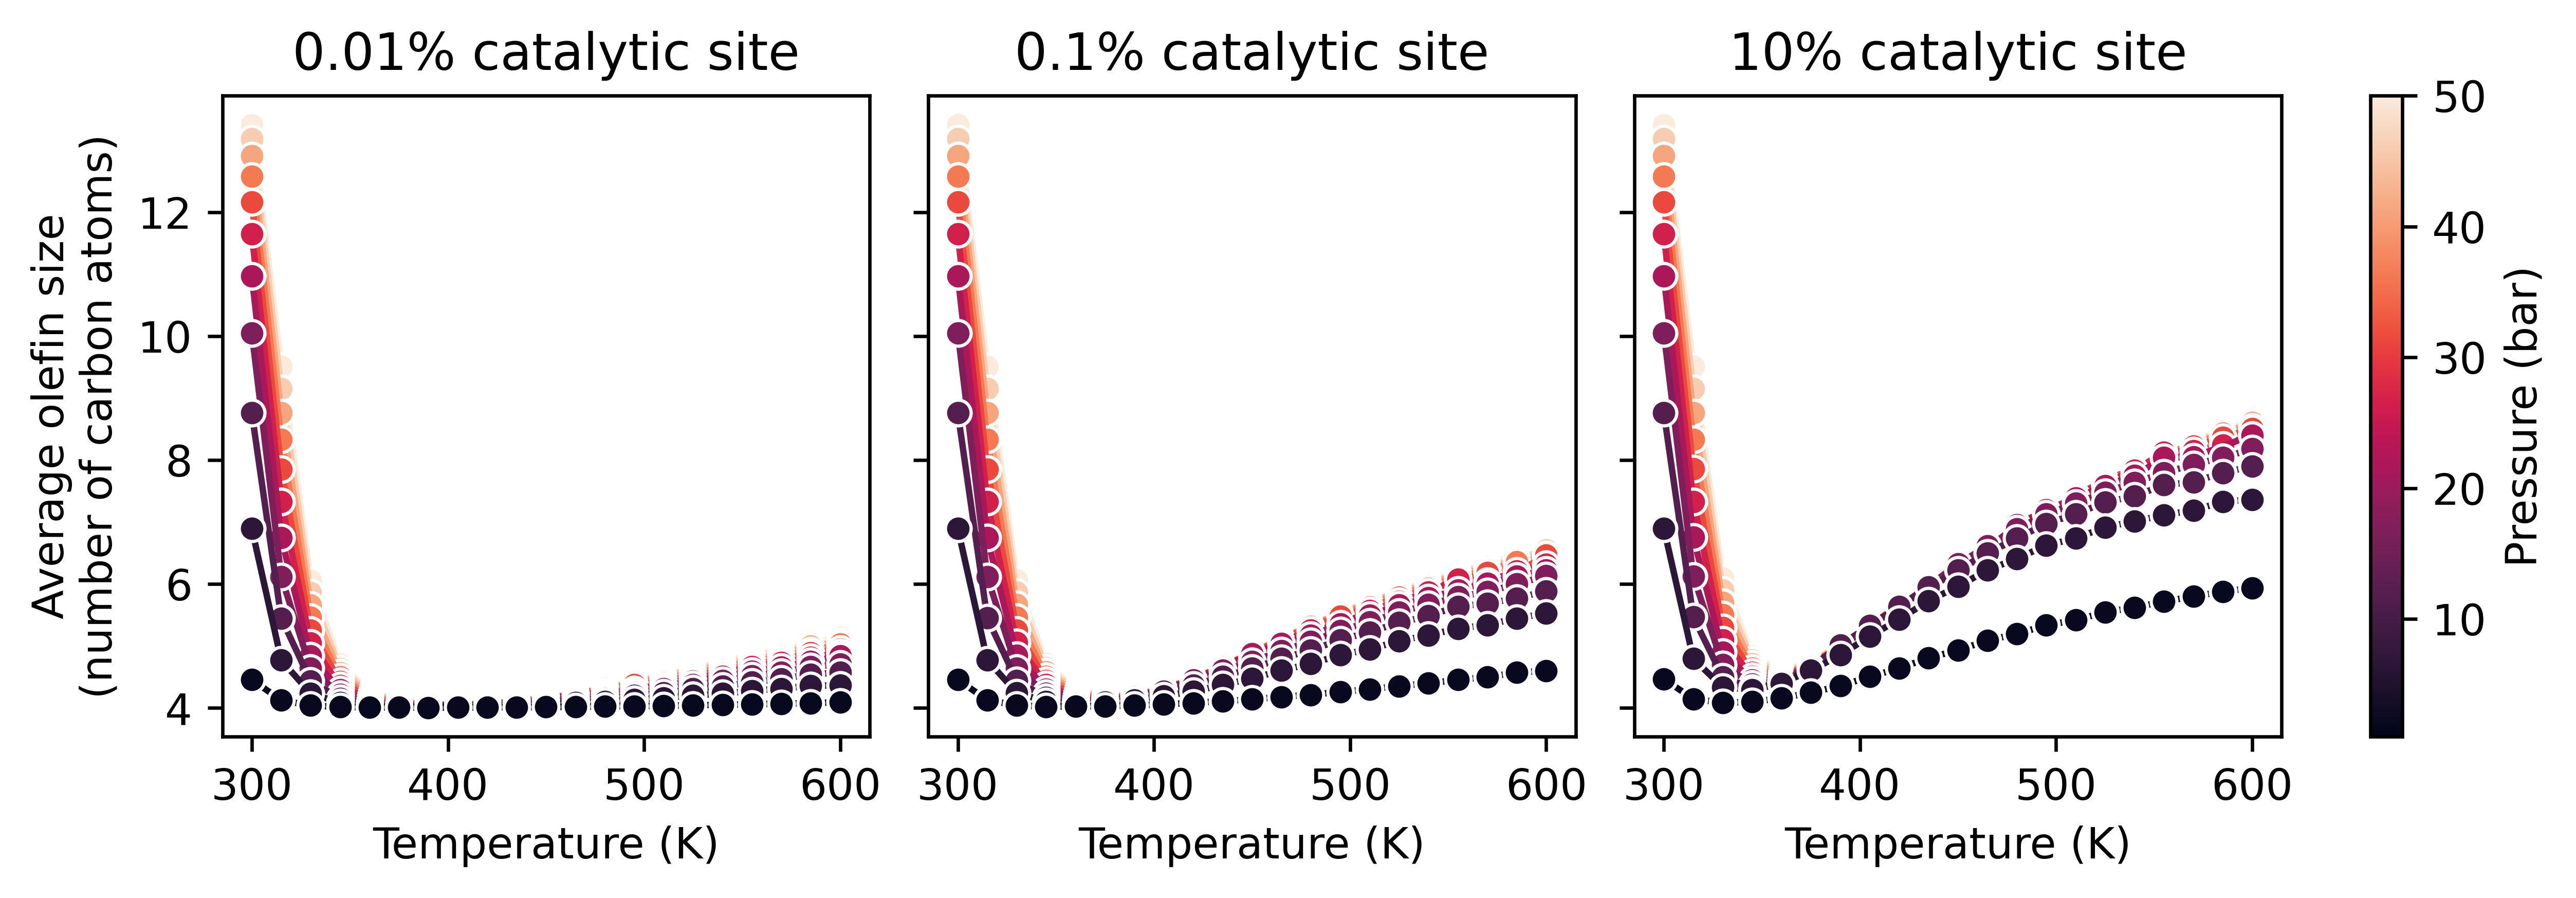

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic_flow#.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, cat_conc, ax) in enumerate([
    (int(1e5), True, True, 0.001, axs[0]),
    (int(1e5), True, True, 0.01, axs[1]),
    (int(1e5), True, True, 0.1, axs[2]),
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == {cat_conc}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    data.loc[:, 'pressure'] = 50 - data.pressure
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('0.01% catalytic site', '0.1% catalytic site', '10% catalytic site'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Average olefin size\n(number of carbon atoms)')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_SI_cat_conc_flow.png", bbox_inches="tight")

/tmp/ipykernel_12313/1601392393.py:21: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(
/tmp/ipykernel_12313/1601392393.py:21: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.lineplot(
/tmp/ipykernel_12313/1601392393.py:36: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend().remove()


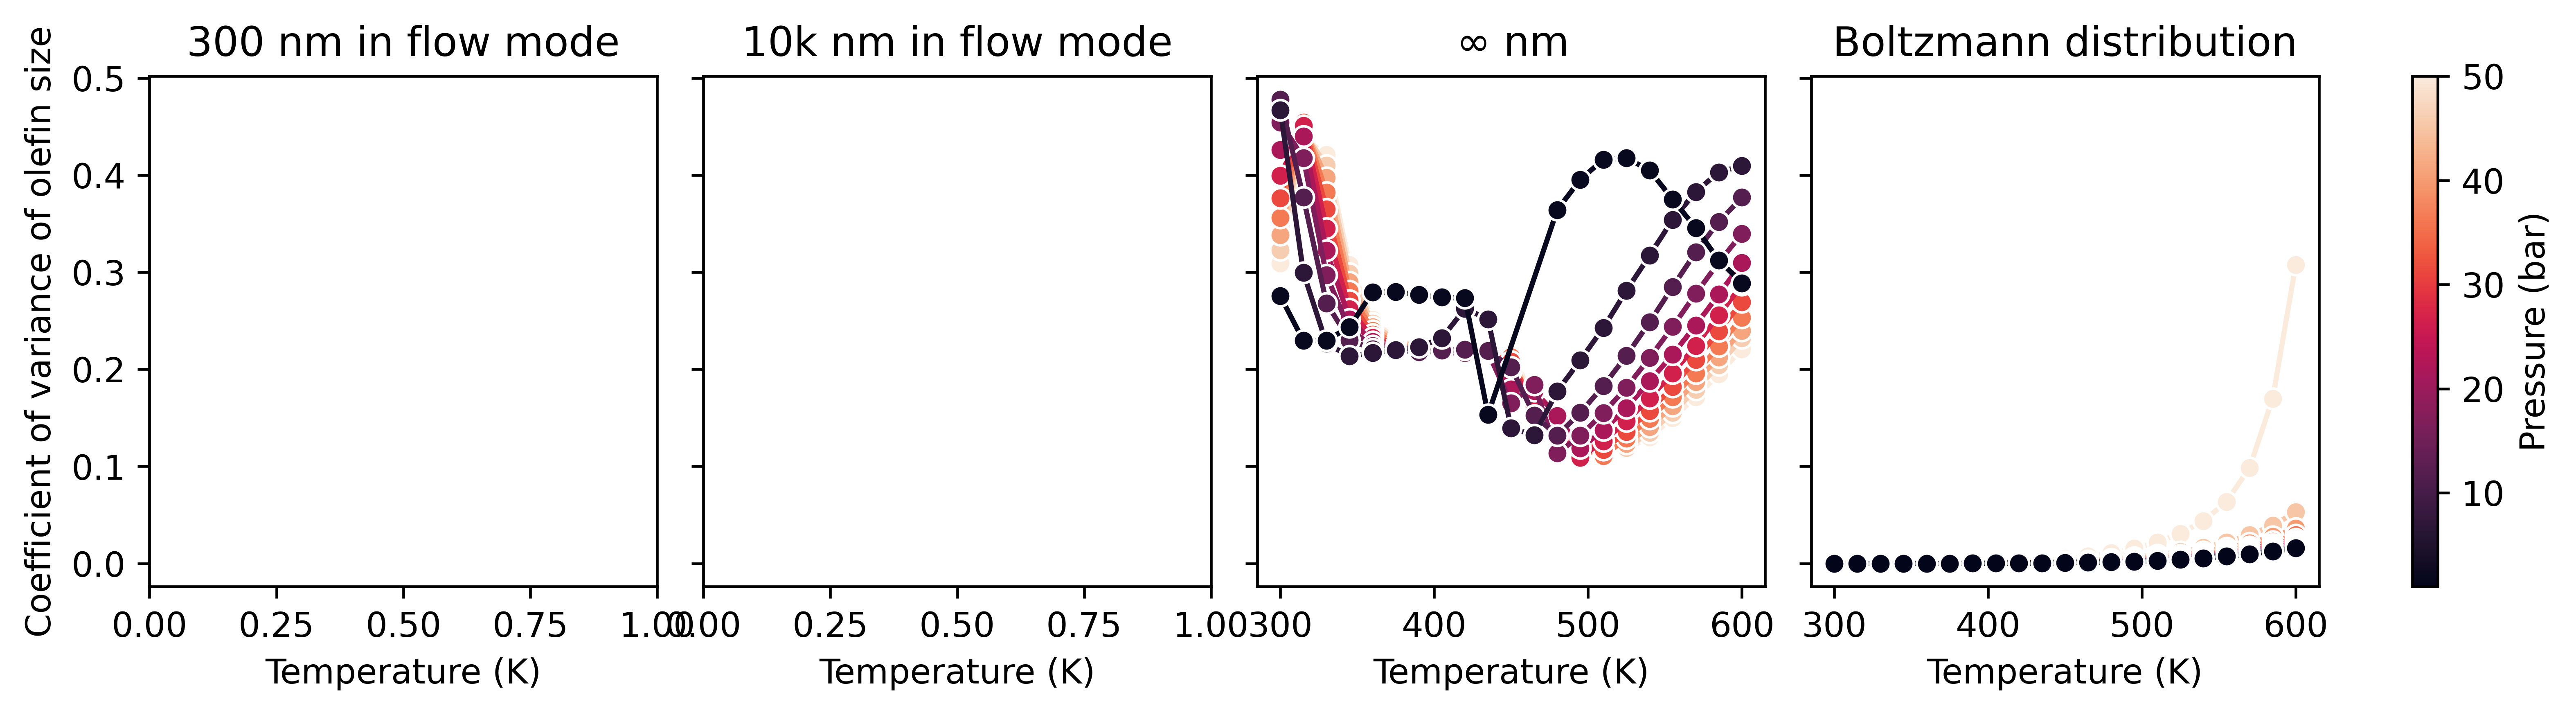

In [17]:
fig, axs = plt.subplots(1, 4, figsize=(12, 2.7), dpi=600, sharey=True)

dft = df_grouped_kinetic.query('cat_conc == 0.01')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, True, axs[0]),
    (10000, True, True, axs[1]),
    (300, True, False, axs[2]),
    (None, None, None, axs[3])
]):
    if psize is None:
        data = df_grouped_boltzman
    else:
        data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream}')
    # Sort so higher pressure values are plotted first (smaller pressures above)
    data.loc[:, 'pressure'] = 50 - data.pressure
    sns.lineplot(
        data=data,
        x='temperature', y='coefficient_variance', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('300 nm in flow mode', '10k nm in flow mode', r'$\infty$ nm', 'Boltzmann distribution'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Coefficient of variance of olefin size')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_CV.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.png", bbox_inches="tight")

In [18]:
df_grouped_kinetic_flow.particle_size.unique()

array([       300,       1000,      10000,     100000,    1000000,
         10000000, 1000000000])

<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
<>:25: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4533/3922280049.py:24: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_xticklabels(['$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$'])
/tmp/ipykernel_4533/3922280049.py:24: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_xticklabels(['$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$'])
/tmp/ipykernel_4533/3922280049.py:25: SyntaxWarning: invalid escape sequence '\m'
  axs[1].set_xticklabels(['$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$'])
/tmp/ipykernel_4533/3922280049.py:25: SyntaxWarning: invalid escape sequence '\m'
  axs[1].set_xticklabels(['$300~nm$', '$100~\mu$

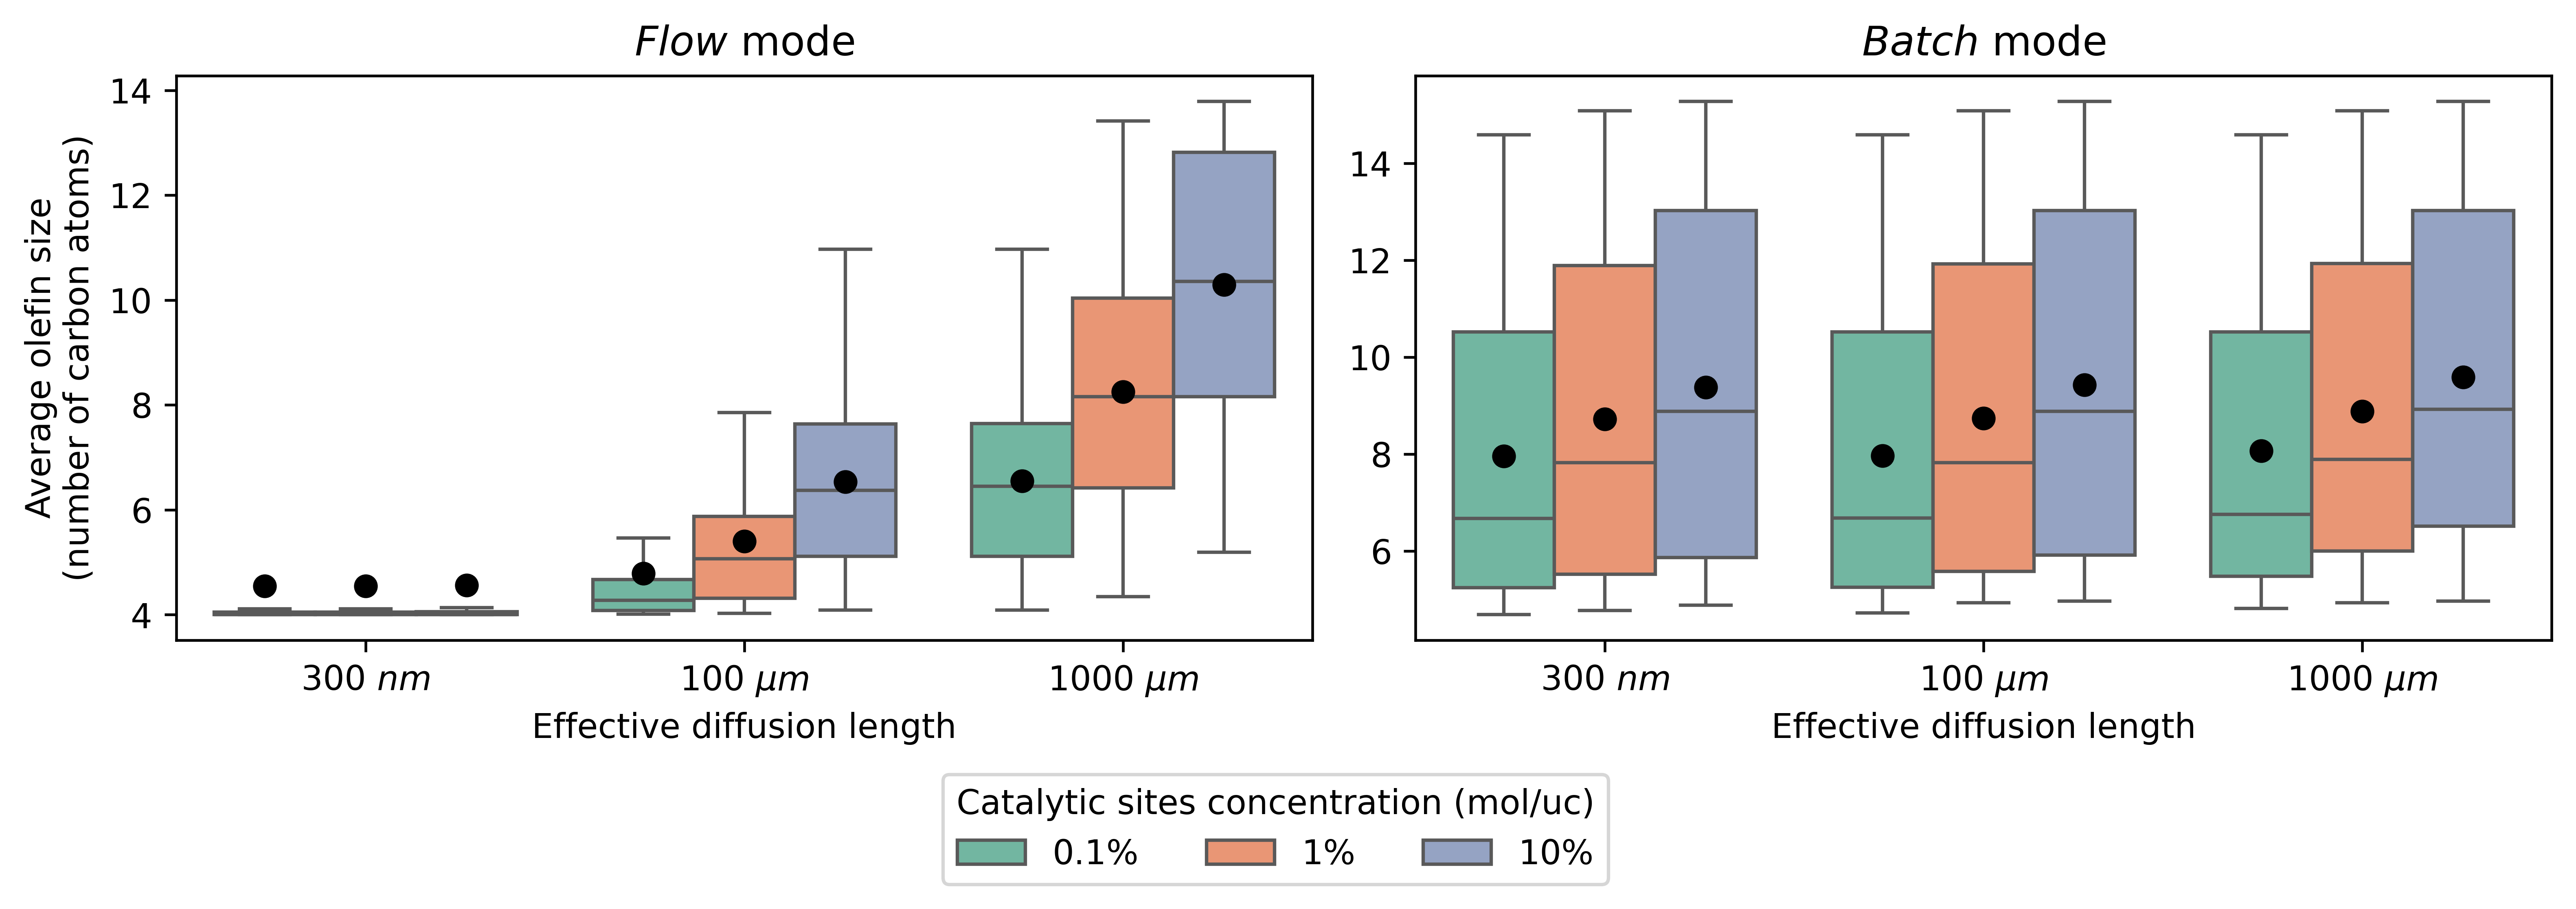

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3), sharey=False, dpi=600)
meanprops = {'marker':'o', 'markerfacecolor':'black', 'markeredgecolor':'black', 'markersize':6}

sns.boxplot(data=df_grouped_kinetic_flow[df_grouped_kinetic_flow.particle_size.isin({300, int(1e5), int(1e6)})], x='particle_size', 
            palette='Set2', showmeans=True, meanprops=meanprops, showfliers=False,
            y='expected_n', hue='cat_conc', ax=axs[0])

sns.boxplot(data=df_grouped_kinetic[df_grouped_kinetic.particle_size.isin({300, int(1e5), int(1e6)})], 
            palette='Set2', showmeans=True, meanprops=meanprops,
            x='particle_size', y='expected_n', hue='cat_conc', ax=axs[1])

axs[0].set_title('$Flow$ mode')
axs[1].set_title('$Batch$ mode')

axs[0].set_ylabel('Average olefin size\n(number of carbon atoms)')
for ax in axs:
    ax.set_xlabel('Effective diffusion length')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()

labels = ['0.1%', '1%', '10%']
axs[0].set_xticklabels(['$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$'])
axs[1].set_xticklabels(['$300~nm$', '$100~\mu$$m$', '$1000~\mu$$m$'])
# axs[1].set_ylim(3, 12)
axs[1].set_ylabel('')
fig.legend(handles, labels, loc='upper center', title='Catalytic sites concentration (mol/uc)', 
           bbox_to_anchor=(0.5, -0.05), ncol=len(labels))



fig.savefig("files/plots/distribution_En_vs_psize.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_vs_psize.svg", bbox_inches="tight")
fig.savefig("files/plots/distribution_En_vs_psize.png", bbox_inches="tight")

In [11]:
palette = sns.color_palette("tab10", n_colors=10)
# palette =  #['#f7fcf5','#e5f5e0','#c7e9c0','#a1d99b','#74c476','#41ab5d','#238b45','#006d2c','#00441b'][1:]

/tmp/ipykernel_4533/2812065478.py:4: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.lineplot(data=ts[ts['temperature'] == 300], x='time', y='concentration',
/tmp/ipykernel_4533/2812065478.py:6: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.lineplot(data=ts[ts['temperature'] == 360], x='time', y='concentration',
/tmp/ipykernel_4533/2812065478.py:8: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.lineplot(data=ts[ts['temperature'] == 390], x='time', y='concentration',
/tmp/ipykernel_4533/2812065478.py:11: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.lineplot(data=ts[ts['temperature'] == 420], x='time', y='concentration',
/tmp/ipykernel_4533/2812065478.py:32: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  axs[0].set_xlim(0, 1e17)


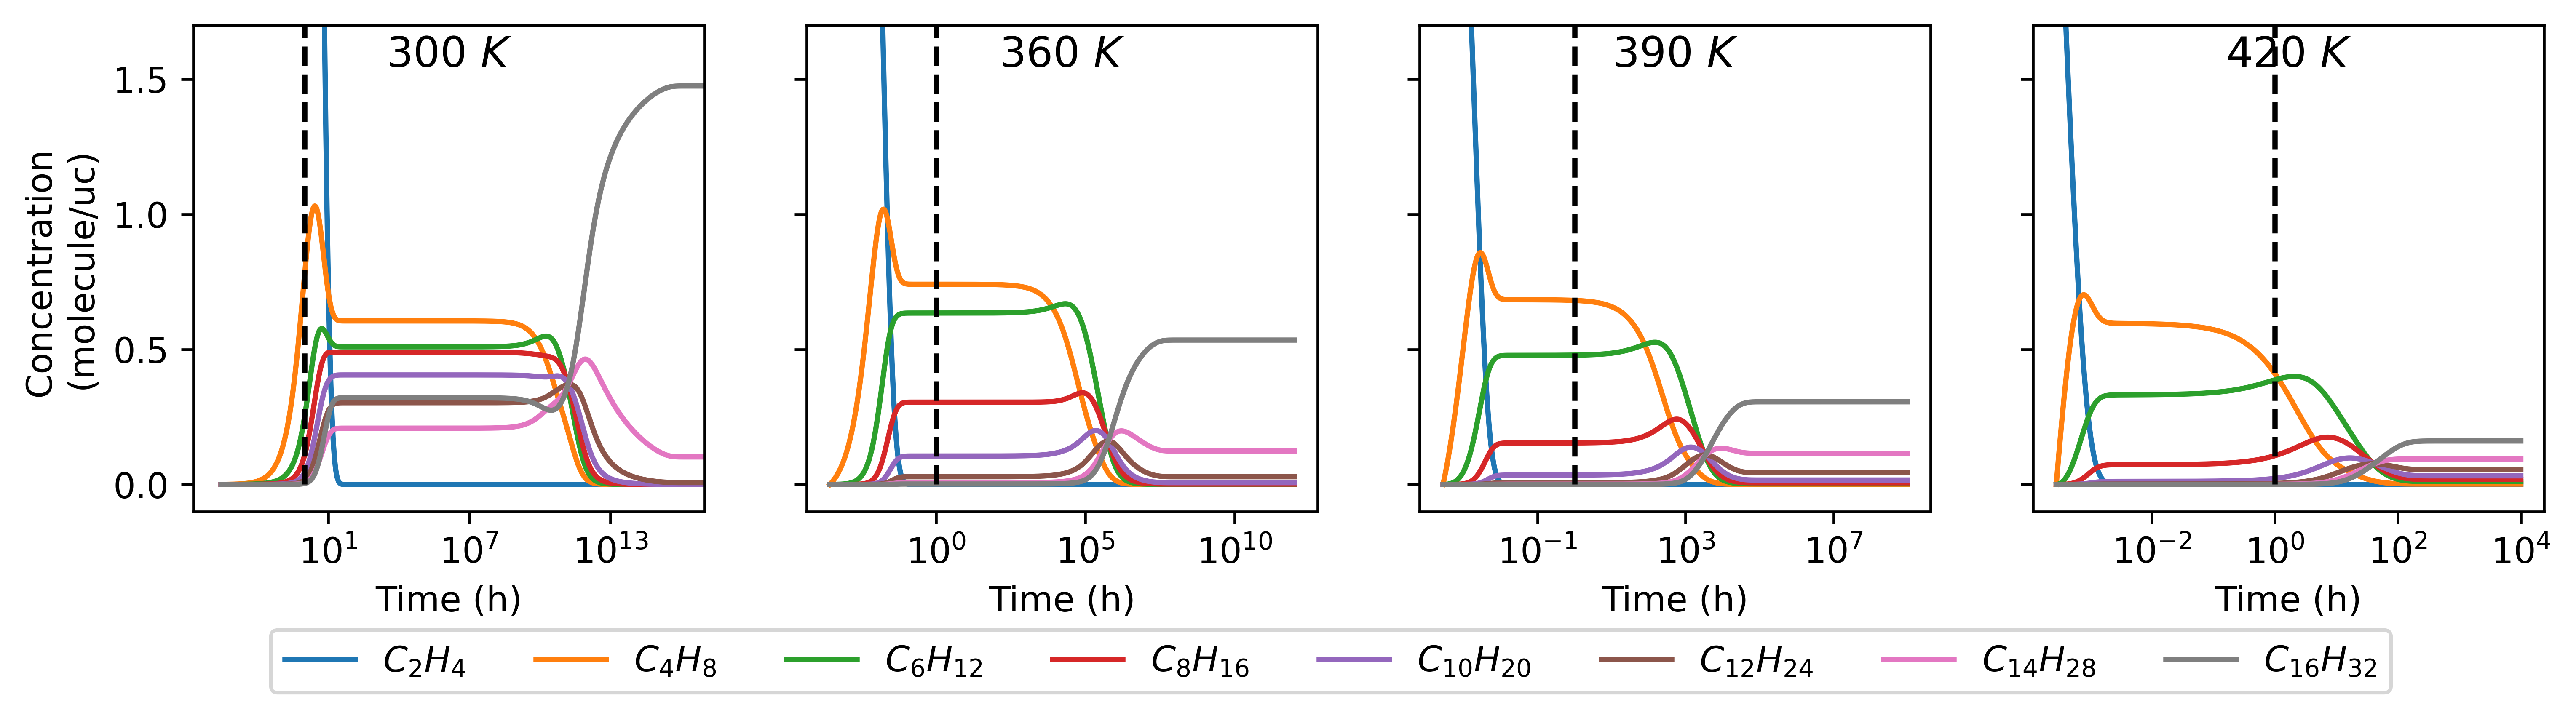

In [12]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 4, figsize=(12, 2.5), dpi=600, sharey=True)

sns.lineplot(data=ts[ts['temperature'] == 300], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[0])
sns.lineplot(data=ts[ts['temperature'] == 360], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[1], legend=False)
sns.lineplot(data=ts[ts['temperature'] == 390], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[2], legend=False)

sns.lineplot(data=ts[ts['temperature'] == 420], x='time', y='concentration', 
             hue='n', palette=palette, ax=axs[3], legend=False)


for ax, text in zip(axs, ['$300~K$', '$360~K$', '$390~K$', '$420~K$']):
    ax.text(
    0.5, 0.98, text,
    transform=ax.transAxes,
    ha='center', va='top', fontsize=12)
    ax.set_ylim([3.5, 14.5])

axs[0].set_ylabel('Concentration \n(molecule/uc)')
axs[0].set_ylim(-0.1, 1.7)
for ax in axs:
    ax.set_xlabel('Time (h)')
    ax.set_ylabel('Concentration \n(molecule/uc)')
    ax.set_xscale('log')
    ax.vlines(1, 0, 5, linestyles='--', color='black')

handles, labels = axs[0].get_legend_handles_labels()
axs[0].legend_.remove()
axs[0].set_xlim(0, 1e17)
labels = [f'$C_{{{label}}}H_{{{2*int(label)}}}$' for label in labels]
fig.legend(handles, labels, bbox_to_anchor=(0.5, -0.05), 
           loc='upper center', ncol=8)

fig.savefig("files/plots/time_evaluation.pdf", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation.svg", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation.png", bbox_inches="tight")

/tmp/ipykernel_4533/1870366548.py:4: UserWarning: The palette list has more values (10) than needed (8), which may not be intended.
  sns.lineplot(data=ts[ts['temperature'] == 300], x='time', y='concentration',


KeyboardInterrupt: 

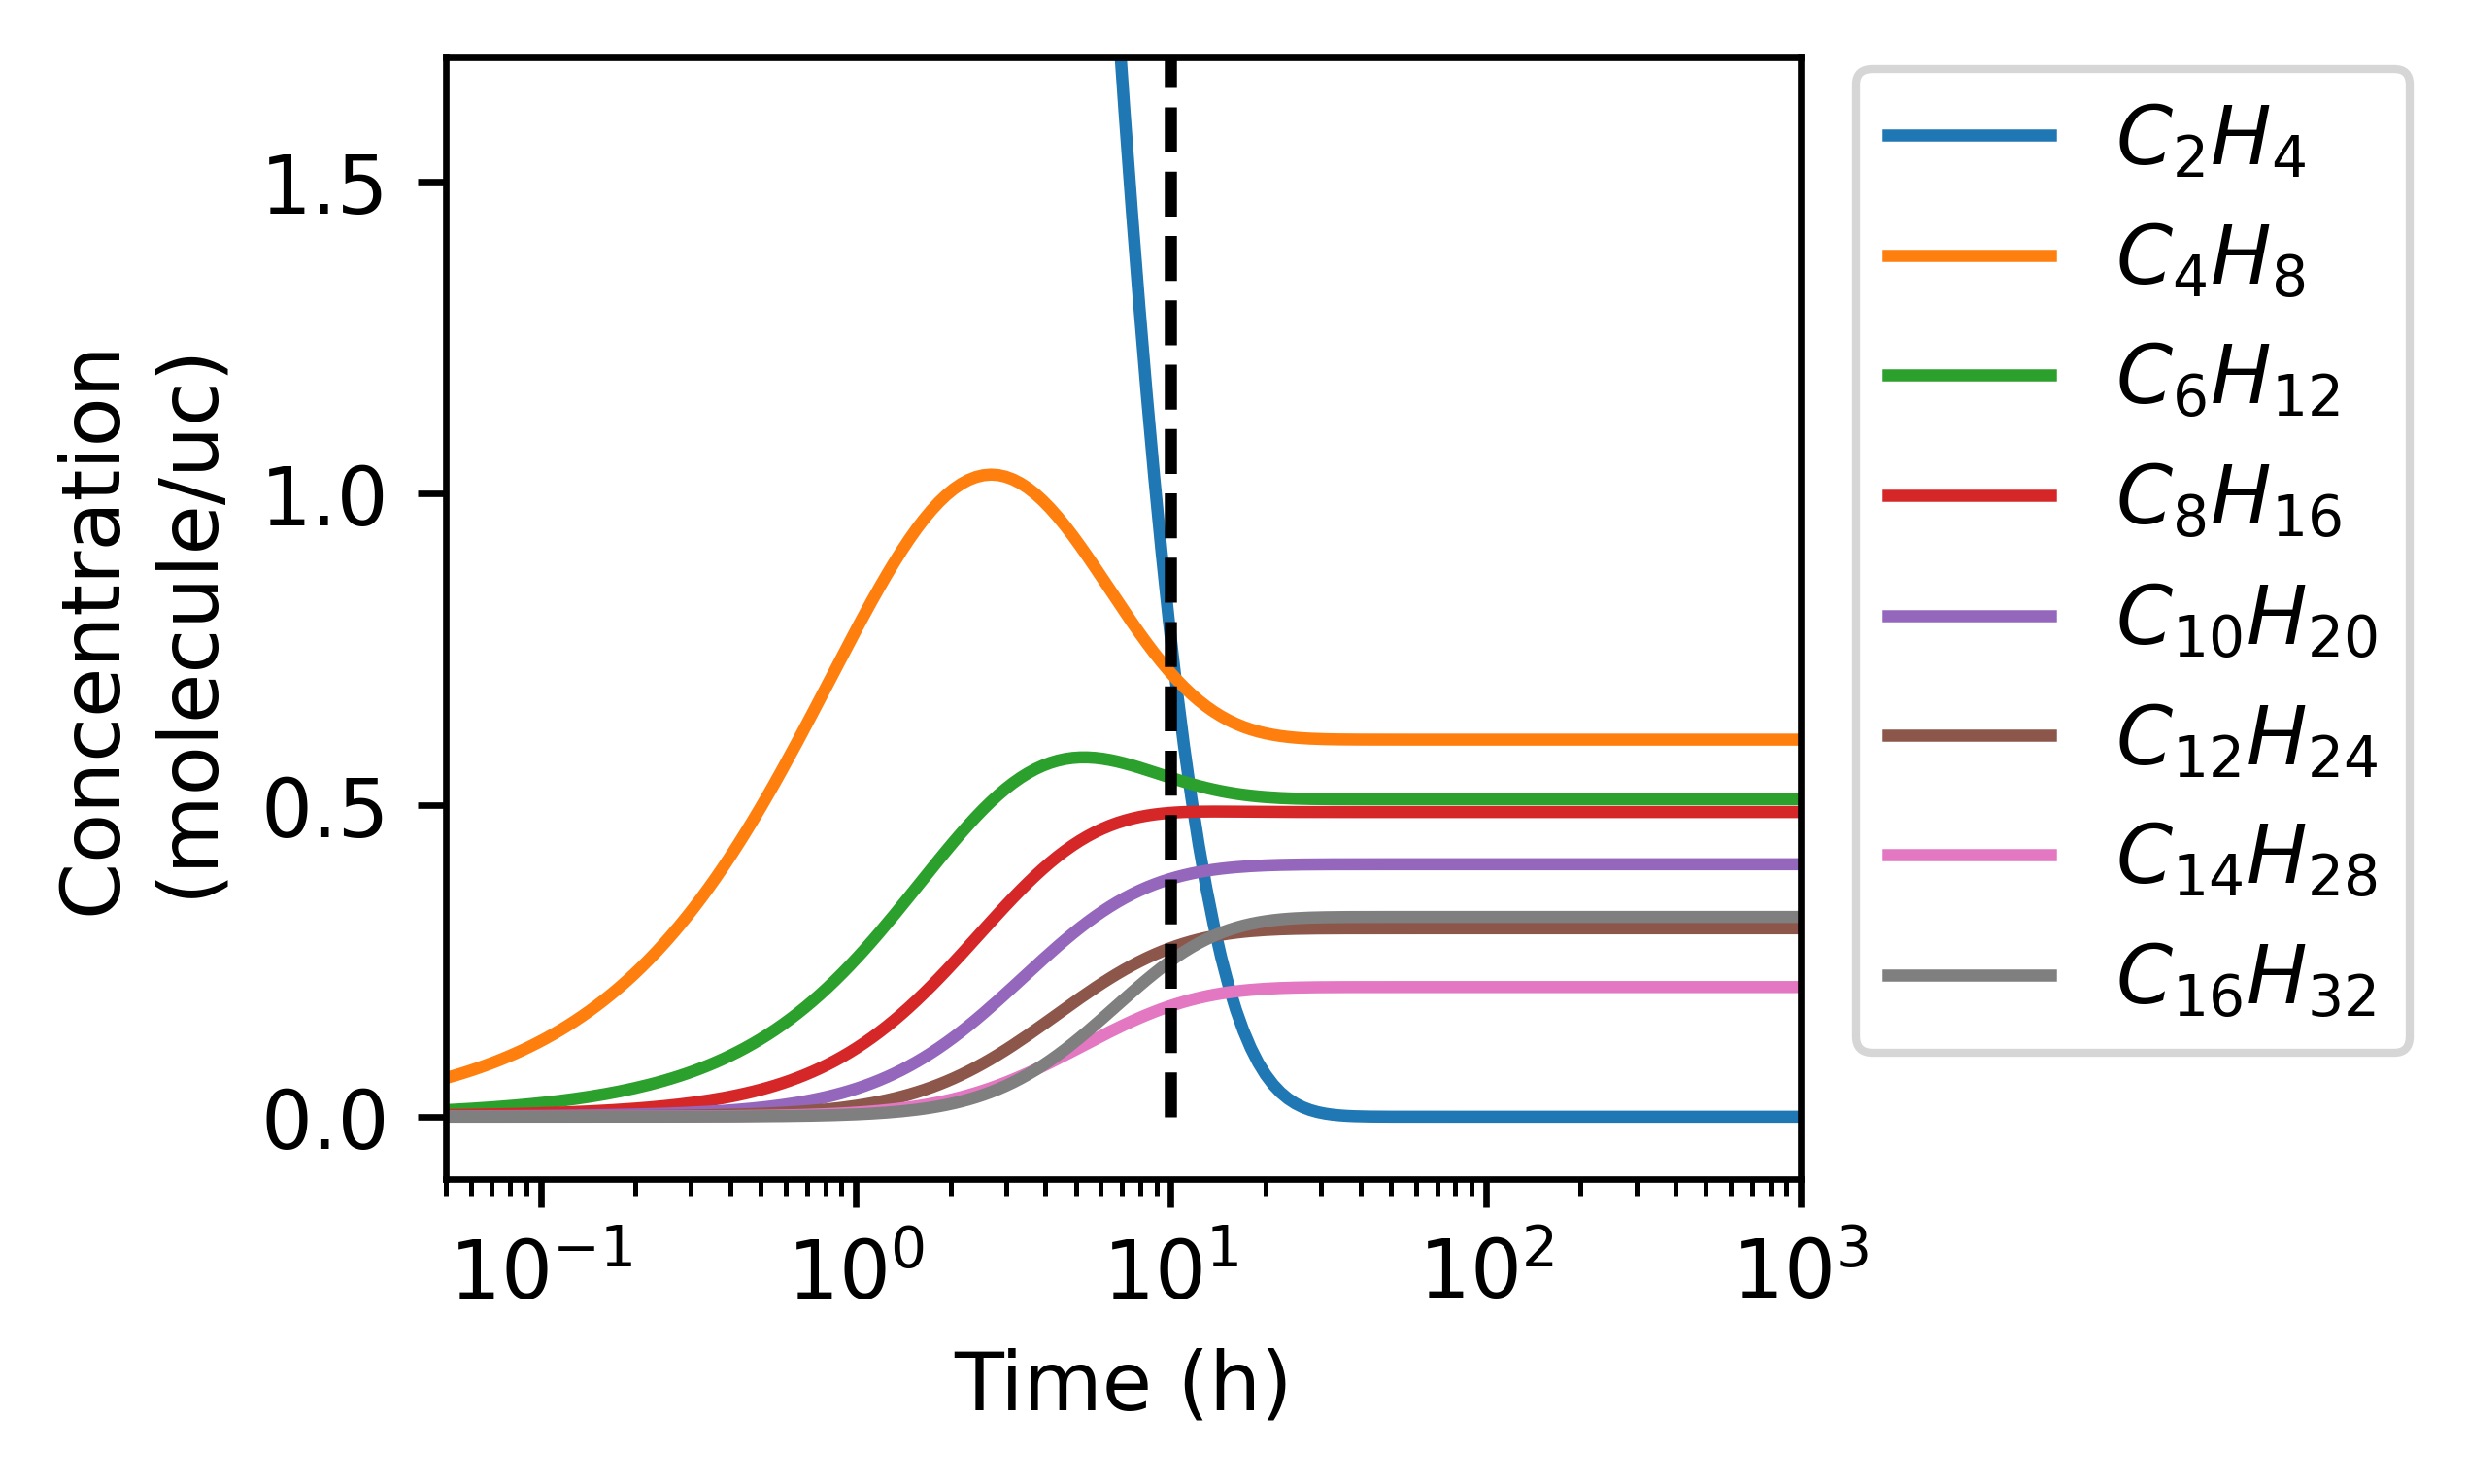

In [13]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 1, figsize=(3, 2.5), dpi=600, sharey=True)

sns.lineplot(data=ts[ts['temperature'] == 300], x='time', y='concentration', 
             hue='n', palette=palette, ax=ax)

# for ax, text in zip(axs, ['$300~K$', '$360~K$', '$390~K$', '$420~K$']):
#     ax.text(
#     0.5, 0.98, text,
#     transform=ax.transAxes,
#     ha='center', va='top', fontsize=12)
#     ax.set_ylim([3.5, 14.5])

ax.set_ylabel('Concentration \n(molecule/uc)')
ax.set_ylim(-0.1, 1.7)
ax.set_xlabel('Time (h)')
ax.set_ylabel('Concentration \n(molecule/uc)')
ax.set_xscale('log')
ax.vlines(10, 0, 5, linestyles='--', color='black')

handles, labels = ax.get_legend_handles_labels()
ax.legend_.remove()
ax.set_xlim(5e-2, 1e3)
labels = [f'$C_{{{label}}}H_{{{2*int(label)}}}$' for label in labels]
fig.legend(handles, labels, bbox_to_anchor=(1.09, 0.9), 
           loc='upper center', ncol=1)

fig.savefig("files/plots/time_evaluation_SI.pdf", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation_SI.svg", bbox_inches="tight")
fig.savefig("files/plots/time_evaluation_SI.png", bbox_inches="tight")

## TOF

In [2]:
folder = 'modeling_C16_10h_corrected_081225'

dft = pd.read_pickle(f'files/{folder}/all_distributions_with_conc.pkl')
               
dft['C2_spent'] = dft['concentration'] * dft.n / 2
dft['TOF'] = dft['concentration']

df_grouped = (dft.groupby(
        ['temperature', 'pressure', 'is_stream', 'diffusion', 'particle_size', 'cat_conc'],
        as_index=False
    )
    .agg(c2_spent=('C2_spent','sum'), TOF=('TOF', 'sum'))
         
)
df_grouped['TOF'] /= 0.01

<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_10333/358721454.py:29: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$10~\mu$$m$', '$100~\mu$$m$', '$1000~\mu$$m$'), axs):
/tmp/ipykernel_10333/358721454.py:29: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$10~\mu$$m$', '$100~\mu$$m$', '$1000~\mu$$m$'), axs):
/tmp/ipykernel_10333/358721454.py:29: SyntaxWarning: invalid escape sequence '\m'
  for title, ax in zip(('$300~nm$', '$10~\mu$$m$', '$100~\mu$$m$', '$1000~\mu$$m$'), axs):


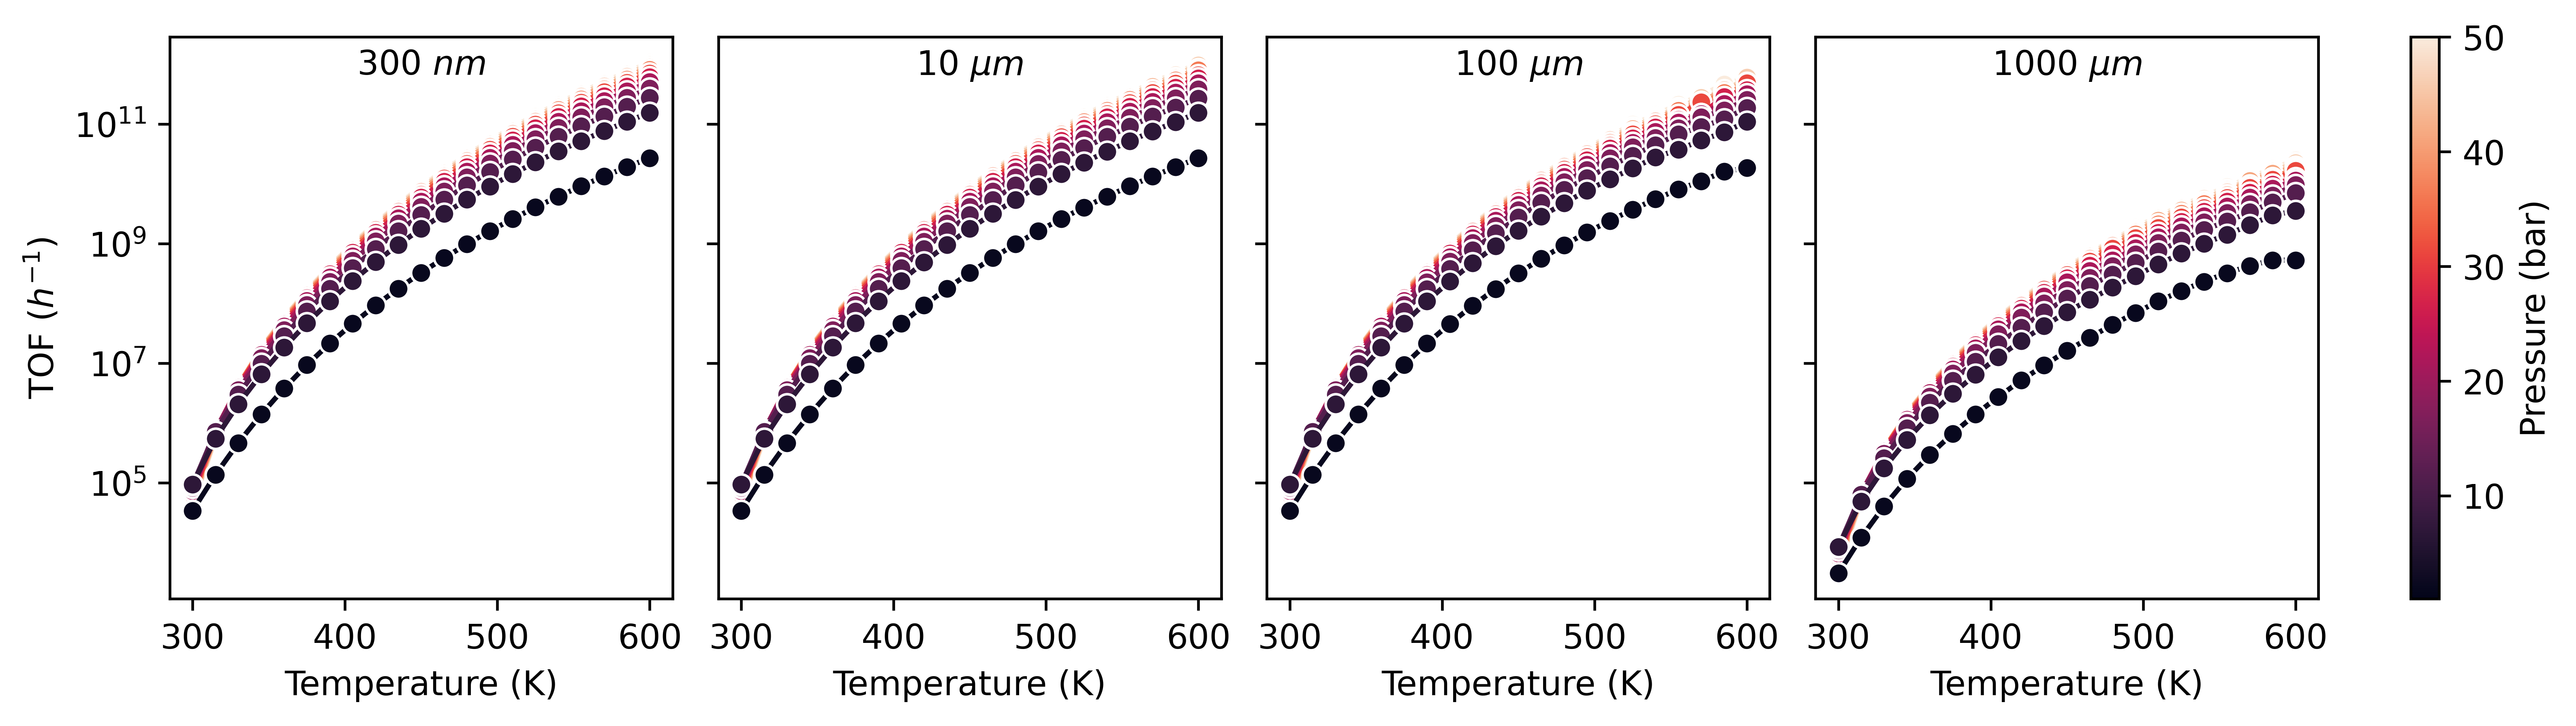

In [3]:
fig, axs = plt.subplots(1, 4, figsize=(12, 3), dpi=600, sharey=True)

cmap = "rocket_r"
cmap_colormap = "rocket"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, is_stream, ax) in enumerate([
    (300, True, True, axs[0]),
    (int(1e4), True, True, axs[1]),
    (int(1e5), True, True, axs[2]),
    (int(1e6), True, True, axs[3]),
]):
    df = df_grouped

    data = df.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"} and is_stream == {is_stream} and cat_conc == 0.01')
    data.loc[:, 'pressure'] = 50 - data.pressure
    # Sort so higher pressure values are plotted first (smaller pressures above)
    sns.lineplot(
        data=data,
        x='temperature', y='TOF', hue='pressure',
        hue_order=sorted(data['pressure'].unique(), reverse=False),
        hue_norm=norm,
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        
    )

for title, ax in zip(('$300~nm$', '$10~\mu$$m$', '$100~\mu$$m$', '$1000~\mu$$m$'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.text(
    0.5, 0.98, title,
    transform=ax.transAxes,
    ha='center', va='top')
    ax.set_yscale('log')


axs[0].set_ylabel('TOF ($h^{-1}$)')
sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/TOF.pdf", bbox_inches="tight")
fig.savefig("files/plots/TOF.svg", bbox_inches="tight")
fig.savefig("files/plots/TOF.png", bbox_inches="tight")

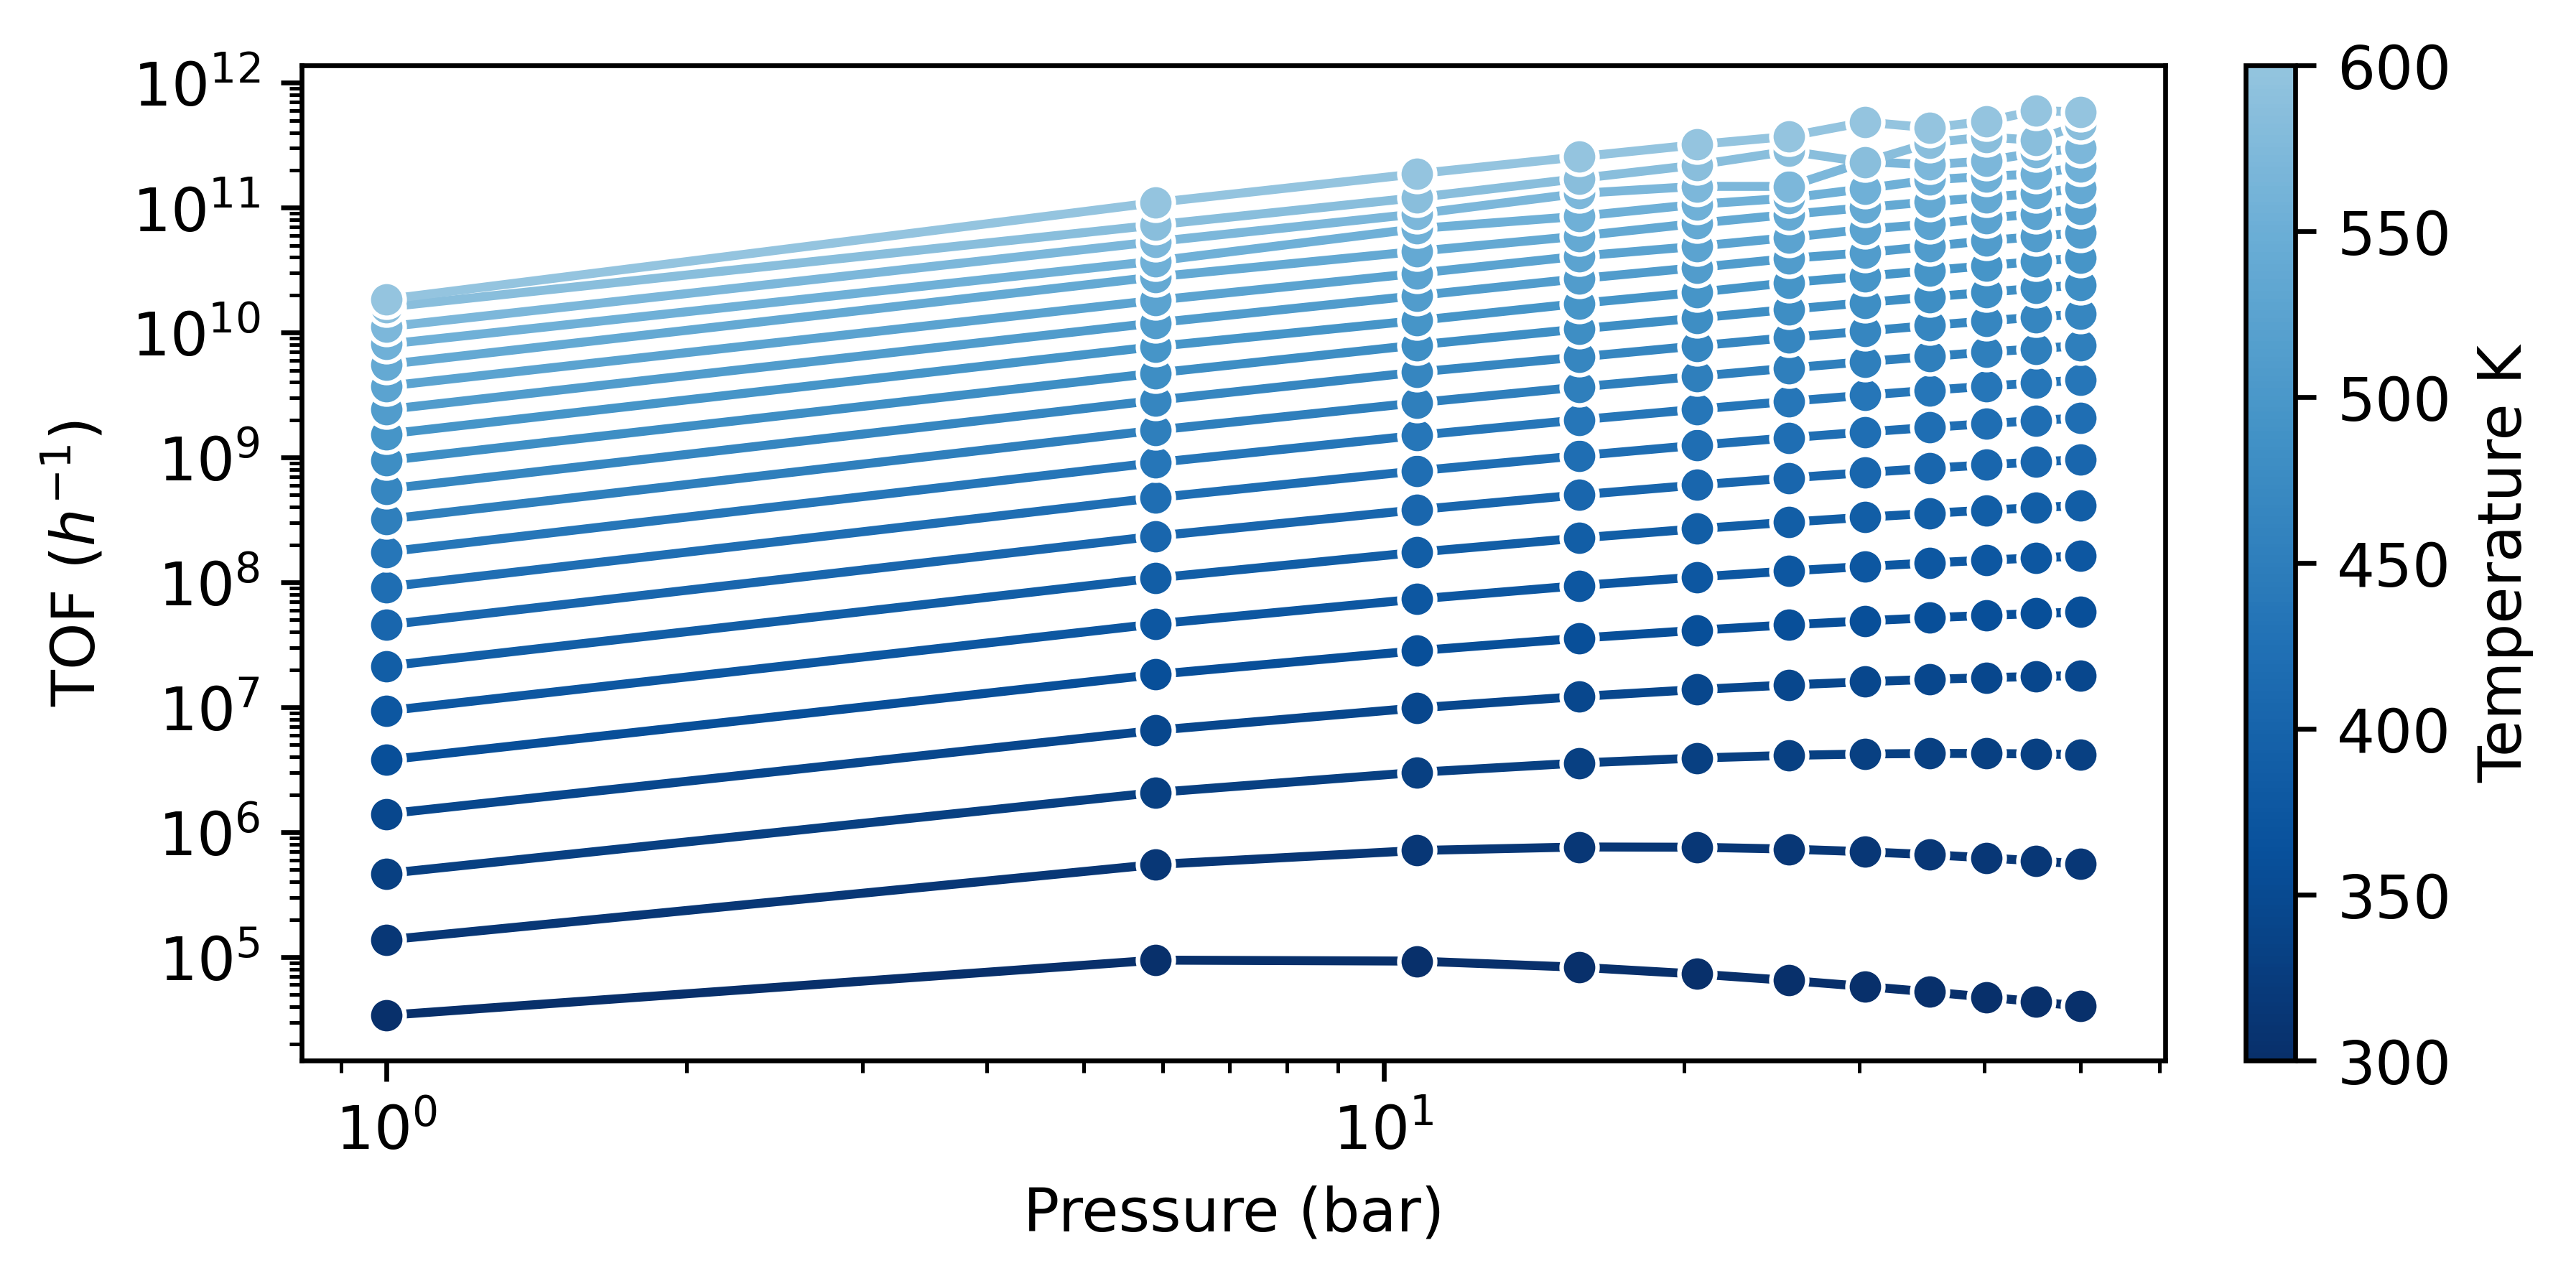

In [24]:
import numpy as np
from matplotlib.colors import LinearSegmentedColormap

orig = plt.get_cmap('Blues_r')


fig, ax = plt.subplots(1, 1, figsize=(6, 3), dpi=600, sharey=True)


norm = mpl.colors.Normalize(vmin=300, vmax=600)

# Keep only 20–100% of the reversed colormap (removes white tail)
clipped = LinearSegmentedColormap.from_list(
    "clippedBlues_r",
    orig(np.linspace(0.0, 0.6, 256))
)

cmap_colormap = clipped
# cmap_colormap = 'Blues_r'
cmap = cmap_colormap
data = df_grouped.query('is_stream and particle_size==100000 and cat_conc==0.01')
# data.loc[:, 'temperature'] = 600 - data.temperature
# Sort so higher pressure values are plotted first (smaller pressures above)
sns.lineplot(
    data=data,
    x='pressure', y='TOF', hue='temperature',
    hue_order=sorted(data['pressure'].unique(), reverse=False),
    hue_norm=norm,
    marker='o', ax=ax,
    palette=cmap,
    
)


ax.set_xlabel('Pressure (bar)')
box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
handles, labels = ax.get_legend_handles_labels()
ax.legend().remove()
ax.set_title('')

ax.set_ylabel('TOF ($h^{-1}$)')

ax.set_yscale('log')
ax.set_xscale('log')

sm = plt.cm.ScalarMappable(cmap=cmap_colormap, norm=norm)
sm.set_array([300, 600])

cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Temperature K')

fig.savefig("files/plots/TOF_press.pdf", bbox_inches="tight")
fig.savefig("files/plots/TOF_press.svg", bbox_inches="tight")
fig.savefig("files/plots/TOF_press.png", bbox_inches="tight")



# Kinetic model schematic

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np 

df = pd.read_pickle(f'files/processed/all_distributions_151025.pkl')
df = df[df.n != 2].copy()

df = df[df.time.between(3602, 3605)]
diffusion = True
is_stream = True
particle_size = 10000
cat_conc = 0.01
temperature = 360
N_max = 10
pressure = df.pressure.unique()[2]
dft = df.query(f'particle_size == {particle_size} and {"diffusion" if diffusion else "not diffusion"} and \
          cat_conc == {cat_conc} \
            and temperature == {temperature} and pressure == {pressure} & n <= {N_max}')
dft
dft['probability'] *= 100

C:\Users\lt0828\AppData\Local\Temp\ipykernel_14096\1702522596.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dft['probability'] *= 100


C:\Users\lt0828\AppData\Local\Temp\ipykernel_14096\157631271.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dft.query('is_stream'), x='n', y='probability',
C:\Users\lt0828\AppData\Local\Temp\ipykernel_14096\157631271.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=dft.query('not is_stream'), x='n', y='probability',
C:\Users\lt0828\AppData\Local\Temp\ipykernel_14096\157631271.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[0].set_xticklabels(labels, fontsize=fs);
C:\Users\lt0828\AppData\Local\Temp\ipykernel_14096\157631271.py:19: UserWarning: set_ticklabels() should only be used w

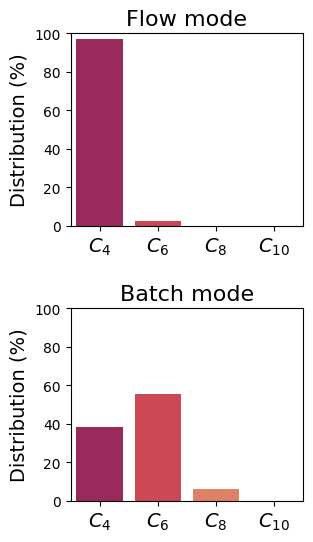

In [5]:
fig, axs = plt.subplots(2, 1, figsize=(3, 5.5))

palette = sns.color_palette("rocket", n_colors=len(dft.n.unique()) + 2)[2:]
# palette = sns.color_palette("Blues_d", n_colors=len(dft.n.unique()) + 2)[::-1]
sns.barplot(data=dft.query('is_stream'), x='n', y='probability', 
            color='skyblue', ax=axs[0], palette=palette)

sns.barplot(data=dft.query('not is_stream'), x='n', y='probability', 
            color='salmon', ax=axs[1], palette=palette)

fs_title = 16
fs = 14
labels = [f'$C_{{{label}}}$' for label in dft.n.unique()]
axs[0].set_title('Flow mode', fontsize=fs_title)
axs[1].set_title('Batch mode', fontsize=fs_title)
axs[0].set_ylabel('Distribution (%)', fontsize=fs)
axs[1].set_ylabel('Distribution (%)', fontsize=fs)
axs[0].set_xticklabels(labels, fontsize=fs);
axs[1].set_xticklabels(labels, fontsize=fs);
axs[0].set_xlabel('')
axs[1].set_xlabel('')
box = axs[1].get_position()
axs[1].set_position([box.x0, box.y0 - 0.08, box.width, box.height])
axs[0].set_ylim(0, 100)
axs[1].set_ylim(0, 100)
# axs[0].set_yticks([])
# axs[1].set_yticks([])
fig.savefig("files/plots/distribution_example.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_example.svg", bbox_inches="tight")